# Generated and saved the segmented inages in Drive

In [ ]:

# ============================================================
# TOMATO SEGMENTATION — SAVE ONLY SEGMENTED IMAGES TO DRIVE
# Method: Hybrid GrabCut + Grey Boundary Refinement
# Output: Segmented PNG images organized by class
# ============================================================

import os
import cv2
import numpy as np

from pathlib import Path
from tqdm.auto import tqdm
from google.colab import drive

# ------------------------------------------------------------
# 1. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive")

# ------------------------------------------------------------
# 2. CONFIGURATION
# ------------------------------------------------------------

SATURATION_THRESHOLD = 45
GRABCUT_ITERATIONS = 5

EDGE_BAND_PIXELS = 8
LOW_SATURATION_THRESHOLD = 65
LOW_VALUE_THRESHOLD = 105

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png"}

# Find the original PlantVillage color dataset.
# If RAW_DATASET_PATH is already defined, it will be reused.
if "RAW_DATASET_PATH" not in globals() or RAW_DATASET_PATH is None:
    possible_paths = [
        Path("/kaggle/input/plantvillage-dataset/plantvillage dataset/color"),
        Path("/kaggle/input/plantvillage-dataset/PlantVillage/color"),
        Path("/kaggle/input/plantvillage-dataset/color"),
        Path("/content/plantvillage-dataset/color"),
    ]

    resolved_path = next(
        (p for p in possible_paths if p.exists()),
        None
    )

    if resolved_path is None:
        try:
            import kagglehub

            print("Locating PlantVillage dataset...")
            download_path = Path(
                kagglehub.dataset_download(
                    "abdallahalidev/plantvillage-dataset"
                )
            )

            candidates = [
                download_path / "plantvillage dataset" / "color",
                download_path / "PlantVillage" / "color",
                download_path / "color",
            ]

            resolved_path = next(
                (p for p in candidates if p.is_dir()),
                None
            )

            if resolved_path is None:
                resolved_path = next(
                    (p for p in download_path.rglob("color")
                     if p.is_dir()),
                    None
                )

        except Exception as error:
            print("Dataset lookup failed:", error)

    if resolved_path is None:
        raise FileNotFoundError(
            "PlantVillage color dataset not found. "
            "Set RAW_DATASET_PATH to its color directory."
        )

    RAW_DATASET_PATH = resolved_path

DATASET_ROOT = Path(RAW_DATASET_PATH)

# A new folder is used so your previous output is not deleted.
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset directory does not exist: {DATASET_ROOT}"
    )

# ------------------------------------------------------------
# 3. DETECT ALL TOMATO CLASSES
# ------------------------------------------------------------

TOMATO_CLASSES = sorted([
    folder.name
    for folder in DATASET_ROOT.iterdir()
    if folder.is_dir()
    and folder.name.startswith("Tomato___")
    and any(
        file.is_file()
        and file.suffix.lower() in SUPPORTED_EXTENSIONS
        for file in folder.iterdir()
    )
])

if not TOMATO_CLASSES:
    raise ValueError(
        f"No Tomato classes found inside {DATASET_ROOT}"
    )

total_images = sum(
    sum(
        1 for file in (DATASET_ROOT / class_name).iterdir()
        if file.is_file()
        and file.suffix.lower() in SUPPORTED_EXTENSIONS
    )
    for class_name in TOMATO_CLASSES
)

print("=" * 60)
print("TOMATO GREY-REFINED SEGMENTATION")
print("=" * 60)
print("Source:", DATASET_ROOT)
print("Drive output:", OUTPUT_DIR)
print("Tomato classes:", len(TOMATO_CLASSES))
print("Original images:", f"{total_images:,}")

for class_name in TOMATO_CLASSES:
    count = sum(
        1 for file in (DATASET_ROOT / class_name).iterdir()
        if file.is_file()
        and file.suffix.lower() in SUPPORTED_EXTENSIONS
    )
    print(f"{class_name}: {count:,} images")

# ------------------------------------------------------------
# 4. HYBRID GRABCUT
# ------------------------------------------------------------

def hybrid_grabcut(image):
    h, w = image.shape[:2]

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    saturation = hsv[:, :, 1]

    mask = np.full(
        (h, w), cv2.GC_PR_BGD, dtype=np.uint8
    )

    mask[saturation >= SATURATION_THRESHOLD] = cv2.GC_PR_FGD

    bx = max(2, int(w * 0.025))
    by = max(2, int(h * 0.025))

    mask[:by, :] = cv2.GC_BGD
    mask[-by:, :] = cv2.GC_BGD
    mask[:, :bx] = cv2.GC_BGD
    mask[:, -bx:] = cv2.GC_BGD

    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)

    cv2.grabCut(
        image, mask, None,
        bg_model, fg_model,
        GRABCUT_ITERATIONS,
        cv2.GC_INIT_WITH_MASK
    )

    return np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

# ------------------------------------------------------------
# 5. RECTANGULAR GRABCUT FALLBACK
# ------------------------------------------------------------

def rectangle_grabcut(image):
    h, w = image.shape[:2]

    rect = (
        int(w * 0.025),
        int(h * 0.025),
        int(w * 0.95),
        int(h * 0.95)
    )

    mask = np.zeros((h, w), dtype=np.uint8)
    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)

    cv2.grabCut(
        image, mask, rect,
        bg_model, fg_model,
        GRABCUT_ITERATIONS,
        cv2.GC_INIT_WITH_RECT
    )

    return np.where(
        (mask == cv2.GC_FGD) |
        (mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

# ------------------------------------------------------------
# 6. FIND EXTERNAL BOUNDARY BAND
# ------------------------------------------------------------

def get_external_edge_band(mask):
    foreground = (mask > 0).astype(np.uint8)

    if np.count_nonzero(foreground) == 0:
        return np.zeros(foreground.shape, dtype=bool)

    contours, _ = cv2.findContours(
        foreground.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    filled_shape = np.zeros_like(foreground)

    cv2.drawContours(
        filled_shape,
        contours,
        -1,
        1,
        thickness=cv2.FILLED
    )

    distance = cv2.distanceTransform(
        filled_shape, cv2.DIST_L2, 3
    )

    return (
        (foreground > 0)
        & (filled_shape > 0)
        & (distance <= EDGE_BAND_PIXELS)
    )

# ------------------------------------------------------------
# 7. GREY BOUNDARY REFINEMENT
# ------------------------------------------------------------

def refine_grey_boundary(image, hybrid_mask):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    saturation = hsv[:, :, 1]
    value = hsv[:, :, 2]

    edge_band = get_external_edge_band(hybrid_mask)

    suspicious_pixels = (
        edge_band
        & (saturation < LOW_SATURATION_THRESHOLD)
        & (value < LOW_VALUE_THRESHOLD)
    )

    final_mask = hybrid_mask.copy()
    final_mask[suspicious_pixels] = 0

    return final_mask

# ------------------------------------------------------------
# 8. SEGMENT AND SAVE IMAGES DIRECTLY TO GOOGLE DRIVE
# ------------------------------------------------------------

processed_count = 0
failed_count = 0
fallback_count = 0
class_counts = {}

print("\nStarting segmentation and Drive saving...\n")

for class_name in TOMATO_CLASSES:
    input_folder = DATASET_ROOT / class_name
    output_folder = OUTPUT_DIR / class_name
    output_folder.mkdir(parents=True, exist_ok=True)

    image_paths = sorted([
        file for file in input_folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in SUPPORTED_EXTENSIONS
    ])

    class_processed = 0

    for image_path in tqdm(image_paths, desc=class_name):
        try:
            image = cv2.imread(
                str(image_path),
                cv2.IMREAD_COLOR
            )

            if image is None:
                failed_count += 1
                continue

            hybrid_mask = hybrid_grabcut(image)

            if np.count_nonzero(hybrid_mask) == 0:
                hybrid_mask = rectangle_grabcut(image)
                fallback_count += 1

            if np.count_nonzero(hybrid_mask) == 0:
                failed_count += 1
                continue

            final_mask = refine_grey_boundary(
                image, hybrid_mask
            )

            if np.count_nonzero(final_mask) == 0:
                final_mask = hybrid_mask

            segmented_image = cv2.bitwise_and(
                image, image, mask=final_mask
            )

            # Save ONLY the segmented image, not the mask.
            output_path = output_folder / f"{image_path.stem}.png"

            saved = cv2.imwrite(
                str(output_path),
                segmented_image,
                [cv2.IMWRITE_PNG_COMPRESSION, 3]
            )

            if not saved:
                failed_count += 1
                continue

            processed_count += 1
            class_processed += 1

        except (cv2.error, OSError, ValueError) as error:
            failed_count += 1
            print(f"\nFailed: {image_path.name} — {error}")

    class_counts[class_name] = class_processed
    print(f"Saved {class_processed:,} images for {class_name}")

# ------------------------------------------------------------
# 9. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SEGMENTATION COMPLETE")
print("=" * 60)

print("Tomato classes found:", len(TOMATO_CLASSES))
print("Original images found:", f"{total_images:,}")
print("Segmented images saved:", f"{processed_count:,}")
print("Failed images:", f"{failed_count:,}")
print("Rectangle GrabCut fallbacks:", f"{fallback_count:,}")

print("\nSaved images per class:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count:,}")

print("\nGoogle Drive output folder:")
print(OUTPUT_DIR)

print("\nOnly segmented PNG images are saved.")
print("No masks, manifests, CSV files, ZIP files, or downloads are created.")


Mounted at /content/drive
Locating PlantVillage dataset...


100%|██████████| 2.04G/2.04G [00:21<00:00, 104MB/s] 

Extracting files...


TOMATO GREY-REFINED SEGMENTATION
Source: /root/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color
Drive output: /content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE
Tomato classes: 10
Original images: 18,160
Tomato___Bacterial_spot: 2,127 images
Tomato___Early_blight: 1,000 images
Tomato___Late_blight: 1,909 images
Tomato___Leaf_Mold: 952 images
Tomato___Septoria_leaf_spot: 1,771 images
Tomato___Spider_mites Two-spotted_spider_mite: 1,676 images
Tomato___Target_Spot: 1,404 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5,357 images
Tomato___Tomato_mosaic_virus: 373 images
Tomato___healthy: 1,591 images

Starting segmentation and Drive saving...



Tomato___Bacterial_spot:   0%|          | 0/2127 [00:00<?, ?it/s]

...

Saved 5,357 images for Tomato___Tomato_Yellow_Leaf_Curl_Virus


Tomato___Tomato_mosaic_virus:   0%|          | 0/373 [00:00<?, ?it/s]

Saved 373 images for Tomato___Tomato_mosaic_virus


Tomato___healthy:   0%|          | 0/1591 [00:00<?, ?it/s]

Saved 1,591 images for Tomato___healthy

SEGMENTATION COMPLETE
Tomato classes found: 10
Original images found: 18,160
Segmented images saved: 18,160
Failed images: 0
Rectangle GrabCut fallbacks: 1

Saved images per class:
Tomato___Bacterial_spot: 2,127
Tomato___Early_blight: 1,000
Tomato___Late_blight: 1,909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1,771
Tomato___Spider_mites Two-spotted_spider_mite: 1,676
Tomato___Target_Spot: 1,404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5,357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1,591

Google Drive output folder:
/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE

Only segmented PNG images are saved.
No masks, manifests, CSV files, ZIP files, or downloads are created.


# Train and Test on OUR segmented

Mounted at /content/drive
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive dataset: /content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE
Local dataset: /content/tomato_grey_refined_segmented
Results folder: /content/drive/MyDrive/tomato_segmented_cnn_new_experiment

Images found in Drive: 18160
Tomato___Bacterial_spot: 2127
Tomato___Early_blight: 1000
Tomato___Late_blight: 1909
Tomato___Leaf_Mold: 952
Tomato___Septoria_leaf_spot: 1771
Tomato___Spider_mites Two-spotted_spider_mite: 1676
Tomato___Target_Spot: 1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357
Tomato___Tomato_mosaic_virus: 373
Tomato___healthy: 1591

Copying dataset to local Colab storage...
This is a one-time copy for the current runtime.
Copy completed in 4.79 minutes.

Local dataset verified: 18160 images

Number of classes: 10
Total images: 18160

Class counts:
class_name
Tomato___Bacterial_spot                          2127
Tomato___Early_blig

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,970 (16.36 MB)

 Trainable params: 4,288,970 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


Testing first training batch...
Batch loaded successfully.
Image shape: (32, 128, 128, 3)
Label shape: (32,)
First batch load time: 5.9 seconds

Starting CNN training...
Epoch 1/50
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.4044 - loss: 1.8088
Epoch 1: val_loss improved from None to 0.94207, saving model to /content/drive/MyDrive/tomato_segmented_cnn_new_experiment/tomato_segmented_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/tomato_segmented_cnn_new_experiment/tomato_segmented_cnn_best.keras

Epoch 1 finished | loss=1.5343 | accuracy=0.5177 | val_loss=0.9421 | val_accuracy=0.6862
364/364 ━━━━━━━━━━━━━━━━━━━━ 39s 69ms/step - accuracy: 0.5177 - loss: 1.5343 - val_accuracy: 0.6862 - val_loss: 0.9421
Epoch 2/50
361/364 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.6721 - loss: 1.0547
Epoch 2: val_loss improved from 0.94207 to 0.72594, saving model to /content/drive/MyDrive/tomato_segmented_cnn_new_experiment/tomato_segmented_cnn_best.keras

Epoc

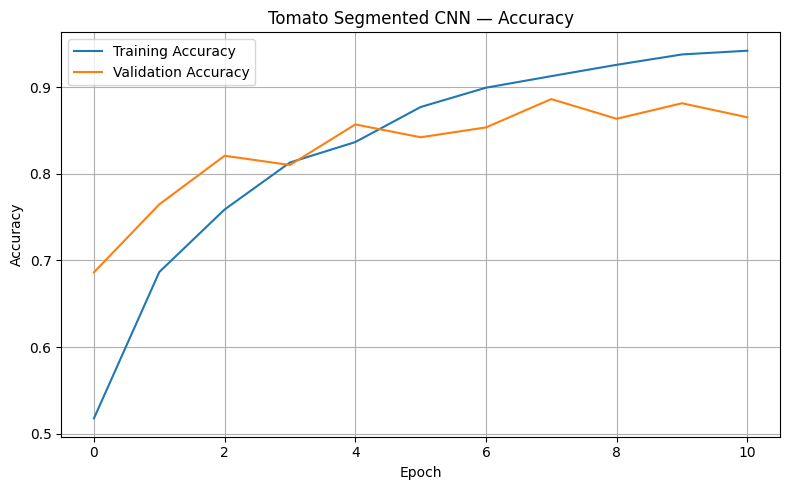

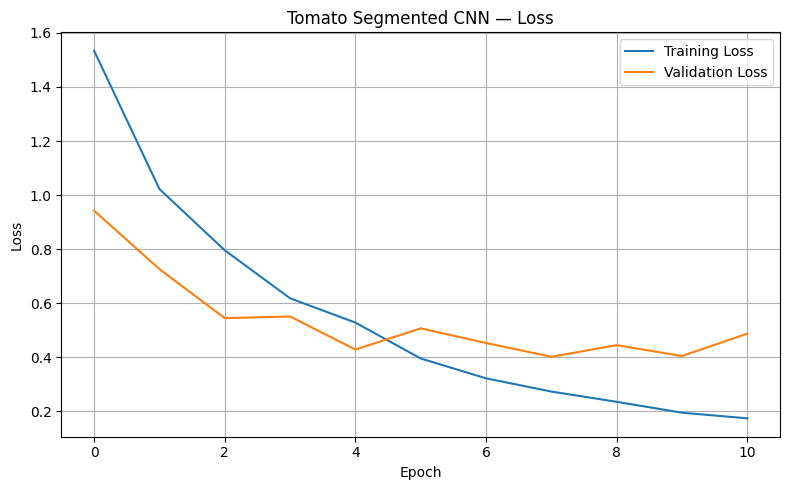

91/91 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.8861 - loss: 0.4012

VALIDATION RESULTS
Validation loss: 0.4012
Validation accuracy: 88.61%
114/114 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.8852 - loss: 0.3588

FINAL TEST RESULTS
Test loss: 0.3588
Test accuracy: 88.52%
114/114 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step

CLASSIFICATION REPORT
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9104    0.8847    0.8974       425
                        Tomato___Early_blight     0.6335    0.7000    0.6651       200
                         Tomato___Late_blight     0.8403    0.8953    0.8669       382
                           Tomato___Leaf_Mold     0.8270    0.8010    0.8138       191
                  Tomato___Septoria_leaf_spot     0.8567    0.7429    0.7958       354
Tomato___Spider_mites Two-spotted_spider_mite     0.9088    0.8925    0.9006       335
                         Tomato___Target_Sp

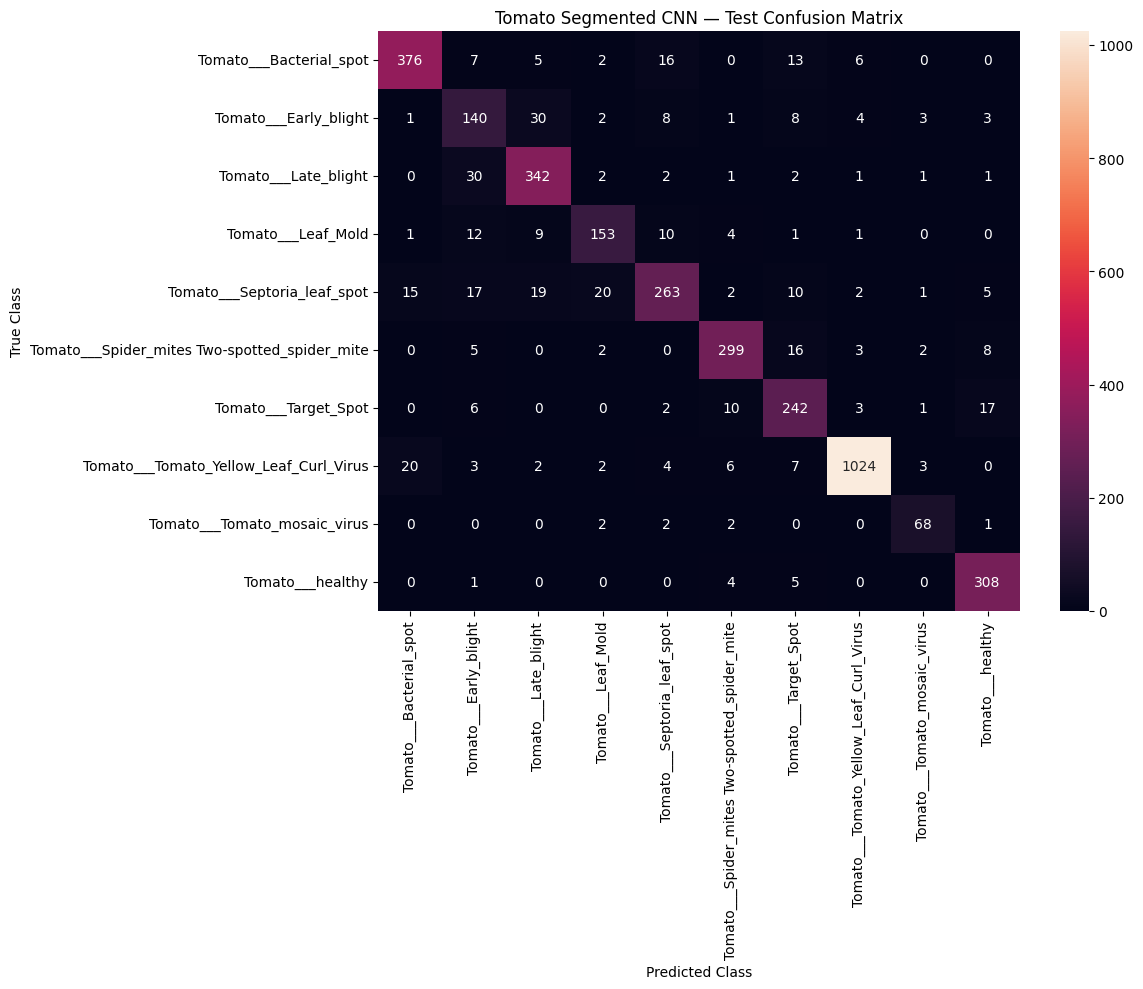


FINAL EXPERIMENT SUMMARY
Classes: 10
Total images: 18160
Training images: 11622
Validation images: 2906
Testing images: 3632
Epochs completed: 11
Final test accuracy: 88.52%
Test set used for training? NO
Test set used for final evaluation? YES

Best model: /content/drive/MyDrive/tomato_segmented_cnn_new_experiment/tomato_segmented_cnn_best.keras
Results folder: /content/drive/MyDrive/tomato_segmented_cnn_new_experiment

Saved files:
- tomato_accuracy_curve.png
- tomato_class_mapping.csv
- tomato_classification_report.csv
- tomato_confusion_matrix.csv
- tomato_confusion_matrix.png
- tomato_loss_curve.png
- tomato_overall_test_metrics.csv
- tomato_segmented_cnn_best.keras
- tomato_segmented_split.csv
- tomato_test_predictions.csv
- tomato_training_history.csv
- tomato_training_log.csv


In [ ]:

# ============================================================
# TOMATO DISEASE CLASSIFICATION — SEGMENTED IMAGES
# FULL TRAINING + FINAL EVALUATION
#
# 64% TRAIN | 16% VALIDATION | 20% TEST
# Fresh CNN training from scratch
# Local image loading for improved performance
# ============================================================

# ============================================================
# 1. IMPORTS
# ============================================================

import os
import time
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 2. CONFIGURATION
# ============================================================

drive.mount("/content/drive")

# Shared segmented dataset shortcut in Google Drive
DRIVE_DATASET = Path(
    "/content/drive/MyDrive/tomato_grey_refined_segmented_COMPLETE"
)

# Local copy: image batches will be read from here
DATASET_DIR = Path(
    "/content/tomato_grey_refined_segmented"
)

# Save results persistently to Drive
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_segmented_cnn_new_experiment"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 50
RANDOM_STATE = 42

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Drive dataset:", DRIVE_DATASET)
print("Local dataset:", DATASET_DIR)
print("Results folder:", OUTPUT_DIR)


# ============================================================
# 3. COPY DATASET FROM DRIVE TO LOCAL STORAGE
# ============================================================

if not DRIVE_DATASET.exists():
    raise FileNotFoundError(
        f"Drive dataset not found: {DRIVE_DATASET}\n"
        "Check the shared-folder shortcut and its path."
    )

def count_class_images(root):
    total = 0
    class_counts = {}

    for folder in sorted(root.iterdir()):
        if folder.is_dir() and folder.name.startswith("Tomato___"):
            count = sum(
                1 for f in folder.iterdir()
                if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
            )
            class_counts[folder.name] = count
            total += count

    return total, class_counts


drive_count, drive_counts = count_class_images(DRIVE_DATASET)

if drive_count == 0:
    raise ValueError(
        "No Tomato images found. Check the dataset folder structure."
    )

print("\nImages found in Drive:", drive_count)
for name, count in drive_counts.items():
    print(f"{name}: {count}")

# Copy only if a complete local copy is not already available.
local_count = 0
if DATASET_DIR.exists():
    local_count, local_counts = count_class_images(DATASET_DIR)

if local_count != drive_count or (
    DATASET_DIR.exists() and local_counts != drive_counts
):
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)

    print("\nCopying dataset to local Colab storage...")
    print("This is a one-time copy for the current runtime.")
    start = time.time()

    shutil.copytree(DRIVE_DATASET, DATASET_DIR)

    print(
        f"Copy completed in {(time.time() - start) / 60:.2f} minutes."
    )
else:
    print("\nComplete local copy already exists; reusing it.")

local_count, local_counts = count_class_images(DATASET_DIR)

if local_count != drive_count or local_counts != drive_counts:
    raise RuntimeError("Local dataset verification failed.")

print("\nLocal dataset verified:", local_count, "images")


# ============================================================
# 4. COLLECT IMAGE PATHS AND LABELS
# ============================================================

class_folders = sorted([
    p for p in DATASET_DIR.iterdir()
    if p.is_dir() and p.name.startswith("Tomato___")
])

if len(class_folders) < 2:
    raise ValueError("At least two Tomato___ class folders are required.")

TOMATO_CLASSES = [p.name for p in class_folders]

class_to_index = {
    name: i for i, name in enumerate(TOMATO_CLASSES)
}

records = []

for folder in class_folders:
    images = sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    if not images:
        raise ValueError(f"No images found in {folder.name}")

    for image_path in images:
        records.append({
            "image_path": str(image_path),
            "class_name": folder.name,
            "label": class_to_index[folder.name]
        })

data_df = pd.DataFrame(records)

print("\nNumber of classes:", len(TOMATO_CLASSES))
print("Total images:", len(data_df))

print("\nClass counts:")
print(data_df["class_name"].value_counts().sort_index())


# Save class mapping
pd.DataFrame({
    "class_name": TOMATO_CLASSES,
    "label": list(range(len(TOMATO_CLASSES)))
}).to_csv(
    OUTPUT_DIR / "tomato_class_mapping.csv",
    index=False
)


# ============================================================
# 5. DATA SPLIT: 64% / 16% / 20%
# ============================================================

train_pool_df, test_df = train_test_split(
    data_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data_df["label"]
)

train_df, val_df = train_test_split(
    train_pool_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=train_pool_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset split:")
print(f"Training:   {len(train_df)} ({100*len(train_df)/len(data_df):.2f}%)")
print(f"Validation: {len(val_df)} ({100*len(val_df)/len(data_df):.2f}%)")
print(f"Testing:    {len(test_df)} ({100*len(test_df)/len(data_df):.2f}%)")

split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

split_df.to_csv(
    OUTPUT_DIR / "tomato_segmented_split.csv",
    index=False
)

print("\nClass-wise split counts:")
print(pd.crosstab(split_df["class_name"], split_df["split"]))


# ============================================================
# 6. IMAGE PREPROCESSING
# ============================================================

def load_and_preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.int32)


def create_dataset(frame, shuffle=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 5000),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


print("\nBuilding datasets...")
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets prepared.")
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))


# ============================================================
# 7. CLASS WEIGHTS
# ============================================================

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(TOMATO_CLASSES)),
    y=train_df["label"].to_numpy()
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:")
for i, name in enumerate(TOMATO_CLASSES):
    print(f"{name}: {class_weights[i]:.4f}")


# ============================================================
# 8. BUILD CNN FROM SCRATCH
# ============================================================

tf.keras.backend.clear_session()
tf.random.set_seed(RANDOM_STATE)

model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    ),

    tf.keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        len(TOMATO_CLASSES),
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN architecture:")
model.summary()


# ============================================================
# 9. VERIFY FIRST BATCH BEFORE TRAINING
# ============================================================

print("\nTesting first training batch...", flush=True)

start = time.time()

for images, labels in train_ds.take(1):
    print("Batch loaded successfully.", flush=True)
    print("Image shape:", images.shape, flush=True)
    print("Label shape:", labels.shape, flush=True)

print(
    "First batch load time:",
    round(time.time() - start, 2),
    "seconds",
    flush=True
)


# ============================================================
# 10. TRAIN CNN
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "tomato_segmented_cnn_best.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "tomato_training_log.csv")
    ),

    # Prints progress at the end of every epoch.
    tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda epoch, logs: print(
            f"\nEpoch {epoch+1} finished | "
            f"loss={logs['loss']:.4f} | "
            f"accuracy={logs['accuracy']:.4f} | "
            f"val_loss={logs['val_loss']:.4f} | "
            f"val_accuracy={logs['val_accuracy']:.4f}",
            flush=True
        )
    )
]

print("\nStarting CNN training...", flush=True)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

print("\nTraining completed.", flush=True)

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    OUTPUT_DIR / "tomato_training_history.csv",
    index=False
)


# ============================================================
# 11. TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Tomato Segmented CNN — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_accuracy_curve.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Tomato Segmented CNN — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_loss_curve.png", dpi=300)
plt.show()


# ============================================================
# 12. VALIDATION AND FINAL TEST EVALUATION
# ============================================================

# The best checkpoint comes from THIS training run.
best_model = tf.keras.models.load_model(str(BEST_MODEL_PATH))

val_loss, val_accuracy = best_model.evaluate(
    val_ds,
    verbose=1
)

print("\nVALIDATION RESULTS")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")

# Test data is used only for final evaluation.
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy*100:.2f}%")


# ============================================================
# 13. CLASSIFICATION REPORT AND METRICS
# ============================================================

probabilities = best_model.predict(test_ds, verbose=1)

y_true = test_df["label"].to_numpy()
y_pred = np.argmax(probabilities, axis=1)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES))),
    target_names=TOMATO_CLASSES,
    digits=4,
    zero_division=0
))

report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(TOMATO_CLASSES))),
        target_names=TOMATO_CLASSES,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    OUTPUT_DIR / "tomato_classification_report.csv"
)

overall_metrics = {
    "test_loss": test_loss,
    "test_accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "weighted_precision": precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_recall": recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "test_image_count": len(y_true)
}

print("\nOVERALL METRICS")
for name, value in overall_metrics.items():
    print(f"{name}: {value}")

pd.DataFrame([overall_metrics]).to_csv(
    OUTPUT_DIR / "tomato_overall_test_metrics.csv",
    index=False
)


# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES)))
)

print("\nCONFUSION MATRIX")
print(cm)

pd.DataFrame(
    cm,
    index=TOMATO_CLASSES,
    columns=TOMATO_CLASSES
).to_csv(
    OUTPUT_DIR / "tomato_confusion_matrix.csv"
)

plt.figure(figsize=(
    max(12, len(TOMATO_CLASSES) * 0.8),
    max(10, len(TOMATO_CLASSES) * 0.7)
))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=TOMATO_CLASSES,
    yticklabels=TOMATO_CLASSES
)

plt.title("Tomato Segmented CNN — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_confusion_matrix.png", dpi=300)
plt.show()


# ============================================================
# 15. SAVE TEST PREDICTIONS AND FINAL SUMMARY
# ============================================================

predictions_df = test_df.copy()
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    TOMATO_CLASSES[i] for i in y_pred
]
predictions_df["confidence"] = np.max(probabilities, axis=1)
predictions_df["correct"] = y_true == y_pred

predictions_df.to_csv(
    OUTPUT_DIR / "tomato_test_predictions.csv",
    index=False
)

print("\n" + "=" * 60)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 60)
print("Classes:", len(TOMATO_CLASSES))
print("Total images:", len(data_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Epochs completed:", len(history.history["loss"]))
print(f"Final test accuracy: {test_accuracy*100:.2f}%")
print("Test set used for training? NO")
print("Test set used for final evaluation? YES")
print("\nBest model:", BEST_MODEL_PATH)
print("Results folder:", OUTPUT_DIR)

print("\nSaved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print("-", file.name)


# Traiin and Test on Raw colored

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Split file: /content/drive/MyDrive/tomato_segmented_cnn_new_experiment/tomato_segmented_split.csv
Results folder: /content/drive/MyDrive/tomato_raw_cnn_fair_comparison

Locating original PlantVillage dataset...


100%|██████████| 2.04G/2.04G [00:22<00:00, 96.0MB/s]

Extracting files...


Original dataset: /root/.cache/kagglehub/datasets/abdallahalidev/plantvillage-dataset/versions/3/plantvillage dataset/color

Number of tomato classes: 10
Total original tomato images: 18160

Class counts:
class_name
Tomato___Bacterial_spot                          2127
Tomato___Early_blight                            1000
Tomato___Late_blight                             1909
Tomato___Leaf_Mold                                952
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___Target_Spot                             1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Tomato_mosaic_virus                      373
Tomato___healthy                                 1591
Name: count, dtype: int64

Successfully reused saved split.

Dataset split:
Training:   11622 (64.00%)
Validation: 2906 (16.00%)
Testing:    3632 (20.00%)

Class-wise split counts:
split                                          test  train  val

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,970 (16.36 MB)

 Trainable params: 4,288,970 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


Testing first training batch...
Batch loaded successfully.
Image shape: (32, 128, 128, 3)
Label shape: (32,)
First batch load time: 3.66 seconds

Starting raw-image CNN training...
Epoch 1/50
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.4077 - loss: 1.7815
Epoch 1: val_loss improved from None to 0.91827, saving model to /content/drive/MyDrive/tomato_raw_cnn_fair_comparison/tomato_raw_cnn_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/tomato_raw_cnn_fair_comparison/tomato_raw_cnn_best.keras

Epoch 1 finished | loss=1.4567 | accuracy=0.5430 | val_loss=0.9183 | val_accuracy=0.6758
364/364 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - accuracy: 0.5430 - loss: 1.4567 - val_accuracy: 0.6758 - val_loss: 0.9183
Epoch 2/50
363/364 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6755 - loss: 1.0757
Epoch 2: val_loss improved from 0.91827 to 0.57709, saving model to /content/drive/MyDrive/tomato_raw_cnn_fair_comparison/tomato_raw_cnn_best.keras

Epoch 2: finished saving m

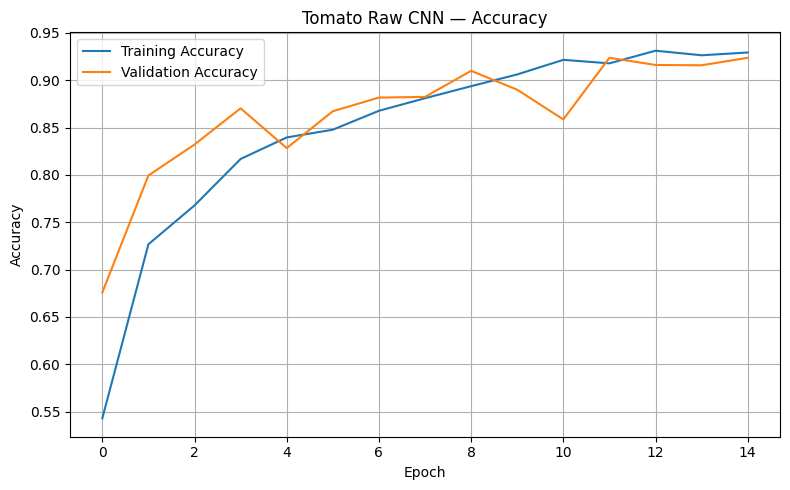

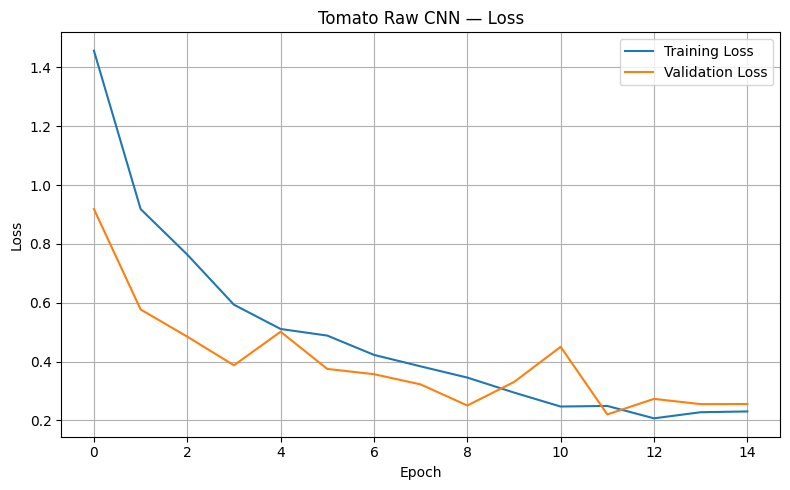

91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9236 - loss: 0.2203

VALIDATION RESULTS
Validation loss: 0.2203
Validation accuracy: 92.36%
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9375 - loss: 0.2047

FINAL TEST RESULTS
Test loss: 0.2047
Test accuracy: 93.75%
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step

CLASSIFICATION REPORT
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9693    0.9671    0.9682       425
                        Tomato___Early_blight     0.8021    0.7500    0.7752       200
                         Tomato___Late_blight     0.8775    0.9188    0.8977       382
                           Tomato___Leaf_Mold     0.8451    0.9424    0.8911       191
                  Tomato___Septoria_leaf_spot     0.9595    0.8701    0.9126       354
Tomato___Spider_mites Two-spotted_spider_mite     0.9037    0.9522    0.9273       335
                         Tomato___Target_Sp

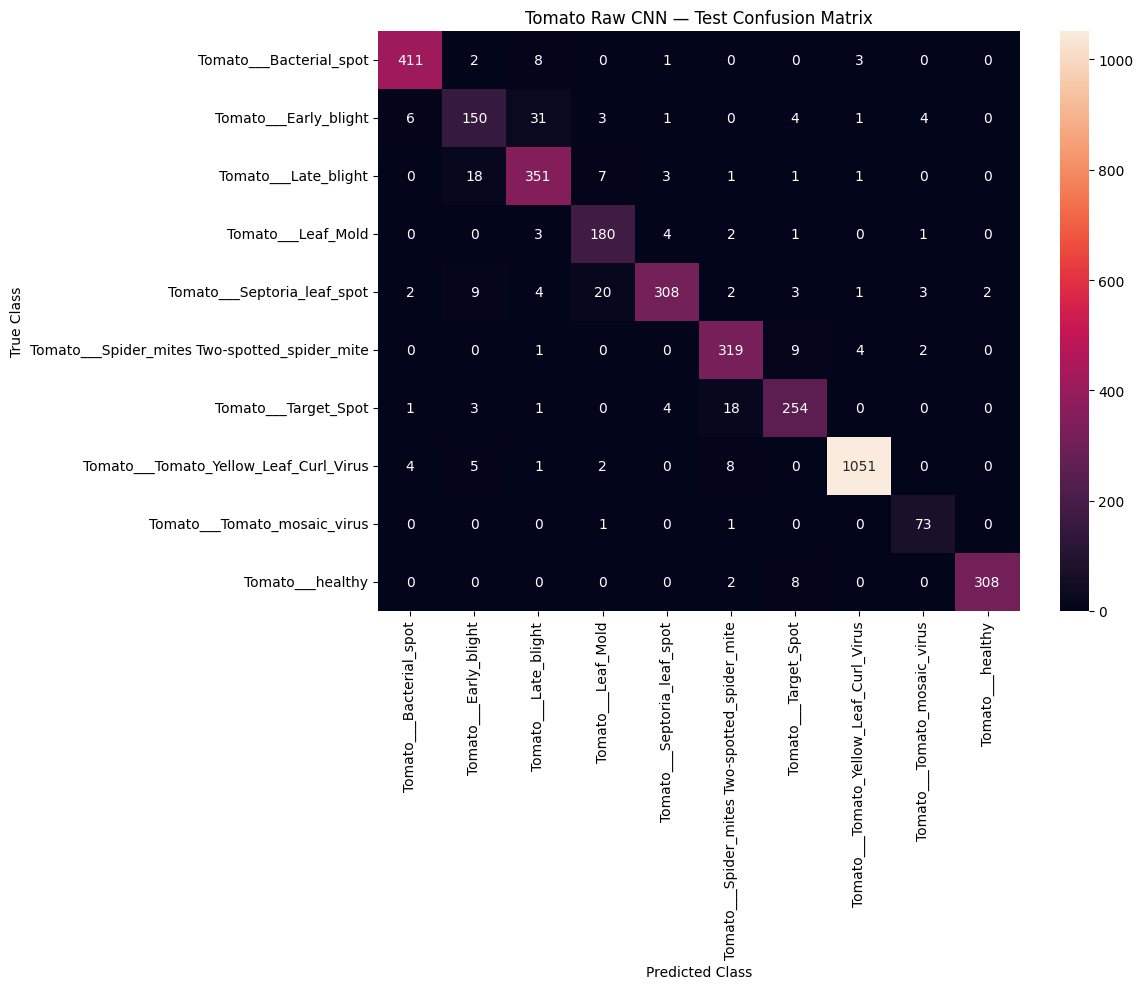


FINAL RAW-IMAGE EXPERIMENT SUMMARY
Classes: 10
Total images: 18160
Training images: 11622
Validation images: 2906
Testing images: 3632
Epochs completed: 15
Final test accuracy: 93.75%
Training time: 3.52 minutes
Test set used for training? NO
Saved segmented split reused? YES

Best model: /content/drive/MyDrive/tomato_raw_cnn_fair_comparison/tomato_raw_cnn_best.keras
Results folder: /content/drive/MyDrive/tomato_raw_cnn_fair_comparison

Saved files:
- tomato_class_mapping.csv
- tomato_raw_accuracy_curve.png
- tomato_raw_classification_report.csv
- tomato_raw_cnn_best.keras
- tomato_raw_confusion_matrix.csv
- tomato_raw_confusion_matrix.png
- tomato_raw_loss_curve.png
- tomato_raw_overall_test_metrics.csv
- tomato_raw_split.csv
- tomato_raw_test_predictions.csv
- tomato_raw_training_history.csv
- tomato_raw_training_log.csv


In [ ]:

# ============================================================
# TOMATO DISEASE CLASSIFICATION — ORIGINAL RAW IMAGES
# FULL TRAINING + FINAL EVALUATION
#
# 64% TRAIN | 16% VALIDATION | 20% TEST
# Uses saved split from segmented experiment in Google Drive
# Same CNN architecture and training settings
# ============================================================

# ============================================================
# 1. IMPORTS
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from pathlib import Path
from google.colab import drive

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# 2. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

# ============================================================
# 3. CONFIGURATION
# ============================================================

IMAGE_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 50
RANDOM_STATE = 42

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Saved split from the previous segmented CNN experiment.
SPLIT_FILE = Path(
    "/content/drive/MyDrive/"
    "tomato_segmented_cnn_new_experiment/"
    "tomato_segmented_split.csv"
)

# Save raw CNN results separately.
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_raw_cnn_fair_comparison"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Split file:", SPLIT_FILE)
print("Results folder:", OUTPUT_DIR)

if not SPLIT_FILE.is_file():
    raise FileNotFoundError(
        f"Saved split CSV not found:\n{SPLIT_FILE}\n"
        "Check the file's location in Google Drive."
    )

# ============================================================
# 4. DOWNLOAD / LOCATE ORIGINAL PLANTVILLAGE DATASET
# ============================================================

print("\nLocating original PlantVillage dataset...")

download_path = Path(
    kagglehub.dataset_download(
        "abdallahalidev/plantvillage-dataset"
    )
)

possible_paths = [
    download_path / "plantvillage dataset" / "color",
    download_path / "PlantVillage" / "color",
    download_path / "color"
]

DATASET_DIR = next(
    (p for p in possible_paths if p.is_dir()),
    None
)

if DATASET_DIR is None:
    DATASET_DIR = next(
        (p for p in download_path.rglob("color") if p.is_dir()),
        None
    )

if DATASET_DIR is None:
    raise FileNotFoundError(
        f"Could not find the original color folder under {download_path}"
    )

print("Original dataset:", DATASET_DIR)

# ============================================================
# 5. COLLECT ORIGINAL TOMATO IMAGES
# ============================================================

class_folders = sorted([
    p for p in DATASET_DIR.iterdir()
    if p.is_dir()
    and p.name.startswith("Tomato___")
    and any(
        f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        for f in p.iterdir()
    )
])

if len(class_folders) < 2:
    raise ValueError("At least two Tomato___ classes are required.")

TOMATO_CLASSES = [p.name for p in class_folders]

class_to_index = {
    name: i for i, name in enumerate(TOMATO_CLASSES)
}

records = []

for folder in class_folders:
    images = sorted([
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    for image_path in images:
        records.append({
            "image_path": str(image_path),
            "image_id": image_path.stem,
            "class_name": folder.name,
            "label": class_to_index[folder.name]
        })

data_df = pd.DataFrame(records)

if data_df.empty:
    raise ValueError("No original tomato images were found.")

print("\nNumber of tomato classes:", len(TOMATO_CLASSES))
print("Total original tomato images:", len(data_df))
print("\nClass counts:")
print(data_df["class_name"].value_counts().sort_index())

# ============================================================
# 6. LOAD AND REUSE SAVED SEGMENTED-EXPERIMENT SPLIT
# ============================================================

saved_split = pd.read_csv(SPLIT_FILE)

required_columns = {"image_path", "class_name", "split"}

if not required_columns.issubset(saved_split.columns):
    raise ValueError(
        "Split CSV must contain columns: image_path, class_name, split."
    )

# Match by class and filename stem because original images may be
# JPG while segmented images were saved as PNG.
saved_split["image_id"] = saved_split["image_path"].apply(
    lambda p: Path(str(p)).stem
)

merge_keys = ["class_name", "image_id"]

if saved_split.duplicated(merge_keys).any():
    raise ValueError(
        "Duplicate class + filename entries in the saved split CSV."
    )

if not set(saved_split["split"].dropna().unique()).issubset(
    {"train", "validation", "test"}
):
    raise ValueError(
        "Unexpected split names. Expected train, validation, test."
    )

# Only use tomato classes from the saved experiment.
saved_split = saved_split[
    saved_split["class_name"].isin(TOMATO_CLASSES)
].copy()

# Ensure every original image has a matching saved assignment.
data_df = data_df.merge(
    saved_split[merge_keys + ["split"]],
    on=merge_keys,
    how="left",
    validate="one_to_one"
)

if data_df["split"].isna().any():
    missing = data_df[data_df["split"].isna()]
    print("\nExamples of unmatched original images:")
    print(missing[["class_name", "image_id"]].head(10))

    raise ValueError(
        f"{len(missing)} original images were not found in the saved split. "
        "Check whether the segmented dataset contains every original image "
        "and whether the filenames match."
    )

# Also ensure the saved split does not contain images missing from
# the original dataset.
original_keys = set(zip(data_df["class_name"], data_df["image_id"]))
saved_keys = set(zip(saved_split["class_name"], saved_split["image_id"]))

extra_keys = saved_keys - original_keys

if extra_keys:
    raise ValueError(
        f"{len(extra_keys)} saved split entries have no matching original "
        "image. The datasets may differ; resolve this before comparison."
    )

train_df = data_df[data_df["split"] == "train"].copy().reset_index(drop=True)
val_df = data_df[data_df["split"] == "validation"].copy().reset_index(drop=True)
test_df = data_df[data_df["split"] == "test"].copy().reset_index(drop=True)

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("One of the saved data splits is empty.")

# Verify that every class has a mapping.
for frame in [train_df, val_df, test_df]:
    frame["label"] = frame["class_name"].map(class_to_index)

    if frame["label"].isna().any():
        raise ValueError("A class in the saved split has no label mapping.")

    frame["label"] = frame["label"].astype(int)

print("\nSuccessfully reused saved split.")
print("\nDataset split:")
print(f"Training:   {len(train_df)} ({100*len(train_df)/len(data_df):.2f}%)")
print(f"Validation: {len(val_df)} ({100*len(val_df)/len(data_df):.2f}%)")
print(f"Testing:    {len(test_df)} ({100*len(test_df)/len(data_df):.2f}%)")

print("\nClass-wise split counts:")
print(pd.crosstab(data_df["class_name"], data_df["split"]))

data_df.to_csv(
    OUTPUT_DIR / "tomato_raw_split.csv",
    index=False
)

pd.DataFrame({
    "class_name": TOMATO_CLASSES,
    "label": list(range(len(TOMATO_CLASSES)))
}).to_csv(
    OUTPUT_DIR / "tomato_class_mapping.csv",
    index=False
)

# ============================================================
# 7. IMAGE PREPROCESSING
# ============================================================

def load_and_preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.int32)


def create_dataset(frame, shuffle=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 5000),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


print("\nBuilding datasets...")

train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))

# ============================================================
# 8. CLASS WEIGHTS
# ============================================================

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(TOMATO_CLASSES)),
    y=train_df["label"].to_numpy()
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:")
for i, name in enumerate(TOMATO_CLASSES):
    print(f"{name}: {class_weights[i]:.4f}")

# ============================================================
# 9. BUILD CNN FROM SCRATCH — SAME ARCHITECTURE
# ============================================================

tf.keras.backend.clear_session()
tf.random.set_seed(RANDOM_STATE)

model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    ),

    tf.keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        len(TOMATO_CLASSES),
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN architecture:")
model.summary()

# ============================================================
# 10. VERIFY FIRST BATCH
# ============================================================

print("\nTesting first training batch...", flush=True)

start = time.time()

for images, labels in train_ds.take(1):
    print("Batch loaded successfully.")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

print(
    "First batch load time:",
    round(time.time() - start, 2),
    "seconds"
)

# ============================================================
# 11. TRAIN CNN
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "tomato_raw_cnn_best.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "tomato_raw_training_log.csv")
    ),

    tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda epoch, logs: print(
            f"\nEpoch {epoch+1} finished | "
            f"loss={logs['loss']:.4f} | "
            f"accuracy={logs['accuracy']:.4f} | "
            f"val_loss={logs['val_loss']:.4f} | "
            f"val_accuracy={logs['val_accuracy']:.4f}",
            flush=True
        )
    )
]

print("\nStarting raw-image CNN training...", flush=True)

training_start = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

training_time = time.time() - training_start

print(f"\nTraining completed in {training_time/60:.2f} minutes.")

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / "tomato_raw_training_history.csv",
    index=False
)

# ============================================================
# 12. TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Tomato Raw CNN — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_raw_accuracy_curve.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Tomato Raw CNN — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_raw_loss_curve.png", dpi=300)
plt.show()

# ============================================================
# 13. VALIDATION AND FINAL TEST EVALUATION
# ============================================================

best_model = tf.keras.models.load_model(str(BEST_MODEL_PATH))

val_loss, val_accuracy = best_model.evaluate(val_ds, verbose=1)

print("\nVALIDATION RESULTS")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print("\nFINAL TEST RESULTS")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

# ============================================================
# 14. CLASSIFICATION REPORT AND METRICS
# ============================================================

probabilities = best_model.predict(test_ds, verbose=1)

y_true = test_df["label"].to_numpy()
y_pred = np.argmax(probabilities, axis=1)

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES))),
    target_names=TOMATO_CLASSES,
    digits=4,
    zero_division=0
))

report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(TOMATO_CLASSES))),
        target_names=TOMATO_CLASSES,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    OUTPUT_DIR / "tomato_raw_classification_report.csv"
)

overall_metrics = {
    "test_loss": test_loss,
    "test_accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "weighted_precision": precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_recall": recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "test_image_count": len(y_true),
    "training_time_minutes": training_time / 60
}

print("\nOVERALL METRICS")
for name, value in overall_metrics.items():
    print(f"{name}: {value}")

pd.DataFrame([overall_metrics]).to_csv(
    OUTPUT_DIR / "tomato_raw_overall_test_metrics.csv",
    index=False
)

# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES)))
)

print("\nCONFUSION MATRIX")
print(cm)

pd.DataFrame(
    cm,
    index=TOMATO_CLASSES,
    columns=TOMATO_CLASSES
).to_csv(
    OUTPUT_DIR / "tomato_raw_confusion_matrix.csv"
)

plt.figure(figsize=(
    max(12, len(TOMATO_CLASSES) * 0.8),
    max(10, len(TOMATO_CLASSES) * 0.7)
))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=TOMATO_CLASSES,
    yticklabels=TOMATO_CLASSES
)

plt.title("Tomato Raw CNN — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "tomato_raw_confusion_matrix.png",
    dpi=300
)
plt.show()

# ============================================================
# 16. SAVE TEST PREDICTIONS AND FINAL SUMMARY
# ============================================================

predictions_df = test_df.copy()
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    TOMATO_CLASSES[i] for i in y_pred
]
predictions_df["confidence"] = np.max(probabilities, axis=1)
predictions_df["correct"] = y_true == y_pred

predictions_df.to_csv(
    OUTPUT_DIR / "tomato_raw_test_predictions.csv",
    index=False
)

print("\n" + "=" * 60)
print("FINAL RAW-IMAGE EXPERIMENT SUMMARY")
print("=" * 60)

print("Classes:", len(TOMATO_CLASSES))
print("Total images:", len(data_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Epochs completed:", len(history.history["loss"]))
print(f"Final test accuracy: {test_accuracy*100:.2f}%")
print(f"Training time: {training_time/60:.2f} minutes")
print("Test set used for training? NO")
print("Saved segmented split reused? YES")

print("\nBest model:", BEST_MODEL_PATH)
print("Results folder:", OUTPUT_DIR)

print("\nSaved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print("-", file.name)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Train and test on their Segmented

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Locating PlantVillage dataset...
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Downloaded dataset location: /kaggle/input/plantvillage-dataset

Using segmented folder: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented

Number of tomato classes: 10
Total segmented images: 18160

Class counts:
class_name
Tomato___Bacterial_spot                          2127
Tomato___Early_blight                            1000
Tomato___Late_blight                             1909
Tomato___Leaf_Mold                                952
Tomato___Septoria_leaf_spot                      1771
Tomato___Spider_mites Two-spotted_spider_mite    1676
Tomato___Target_Spot                             1404
Tomato___Tomato_Yellow_Leaf_Curl_Virus           5357
Tomato___Tomato_mosaic_virus                      373
Tomato___healthy                                 1591


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,970 (16.36 MB)

 Trainable params: 4,288,970 (16.36 MB)

 Non-trainable params: 0 (0.00 B)


Testing first training batch...
Batch loaded successfully.
Image shape: (32, 128, 128, 3)
Label shape: (32,)
First batch load time: 11.71 seconds

Starting segmented-image CNN training...
Epoch 1/50
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3634 - loss: 1.7894
Epoch 1: val_loss improved from None to 0.99607, saving model to /content/tomato_dataset_segmented_cnn_experiment/tomato_dataset_segmented_cnn_best.keras

Epoch 1: finished saving model to /content/tomato_dataset_segmented_cnn_experiment/tomato_dataset_segmented_cnn_best.keras

Epoch 1 finished | loss=1.5102 | accuracy=0.4841 | val_loss=0.9961 | val_accuracy=0.6937
364/364 ━━━━━━━━━━━━━━━━━━━━ 35s 78ms/step - accuracy: 0.4841 - loss: 1.5102 - val_accuracy: 0.6937 - val_loss: 0.9961
Epoch 2/50
362/364 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6774 - loss: 1.0185
Epoch 2: val_loss improved from 0.99607 to 0.82456, saving model to /content/tomato_dataset_segmented_cnn_experiment/tomato_dataset_segmented_cnn_best

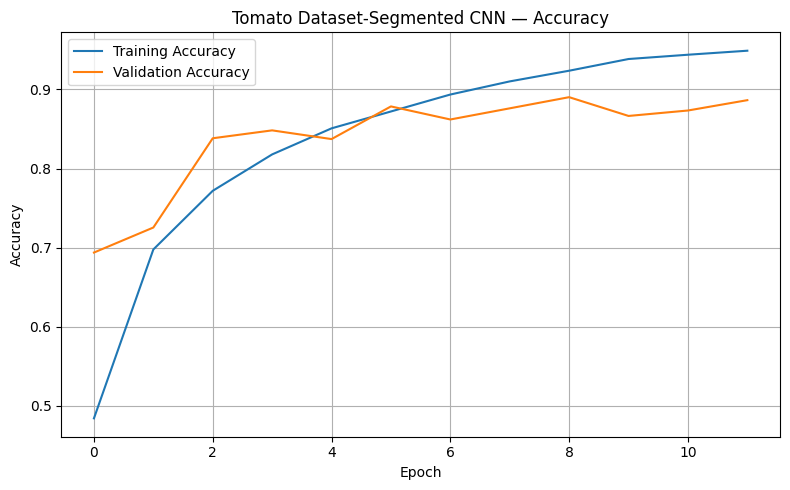

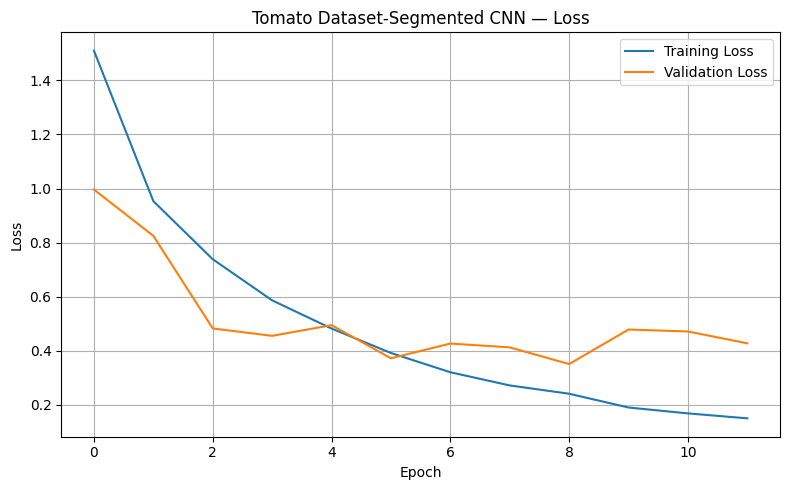

91/91 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.8902 - loss: 0.3500

VALIDATION RESULTS
Validation loss: 0.3500
Validation accuracy: 89.02%
114/114 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.9003 - loss: 0.3682

FINAL TEST RESULTS
Test loss: 0.3682
Test accuracy: 90.03%
114/114 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step

CLASSIFICATION REPORT
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot     0.9410    0.9388    0.9399       425
                        Tomato___Early_blight     0.7039    0.6300    0.6649       200
                         Tomato___Late_blight     0.8214    0.9031    0.8603       382
                           Tomato___Leaf_Mold     0.7991    0.8953    0.8444       191
                  Tomato___Septoria_leaf_spot     0.9106    0.7768    0.8384       354
Tomato___Spider_mites Two-spotted_spider_mite     0.8886    0.9045    0.8964       335
                         Tomato___Target_Sp

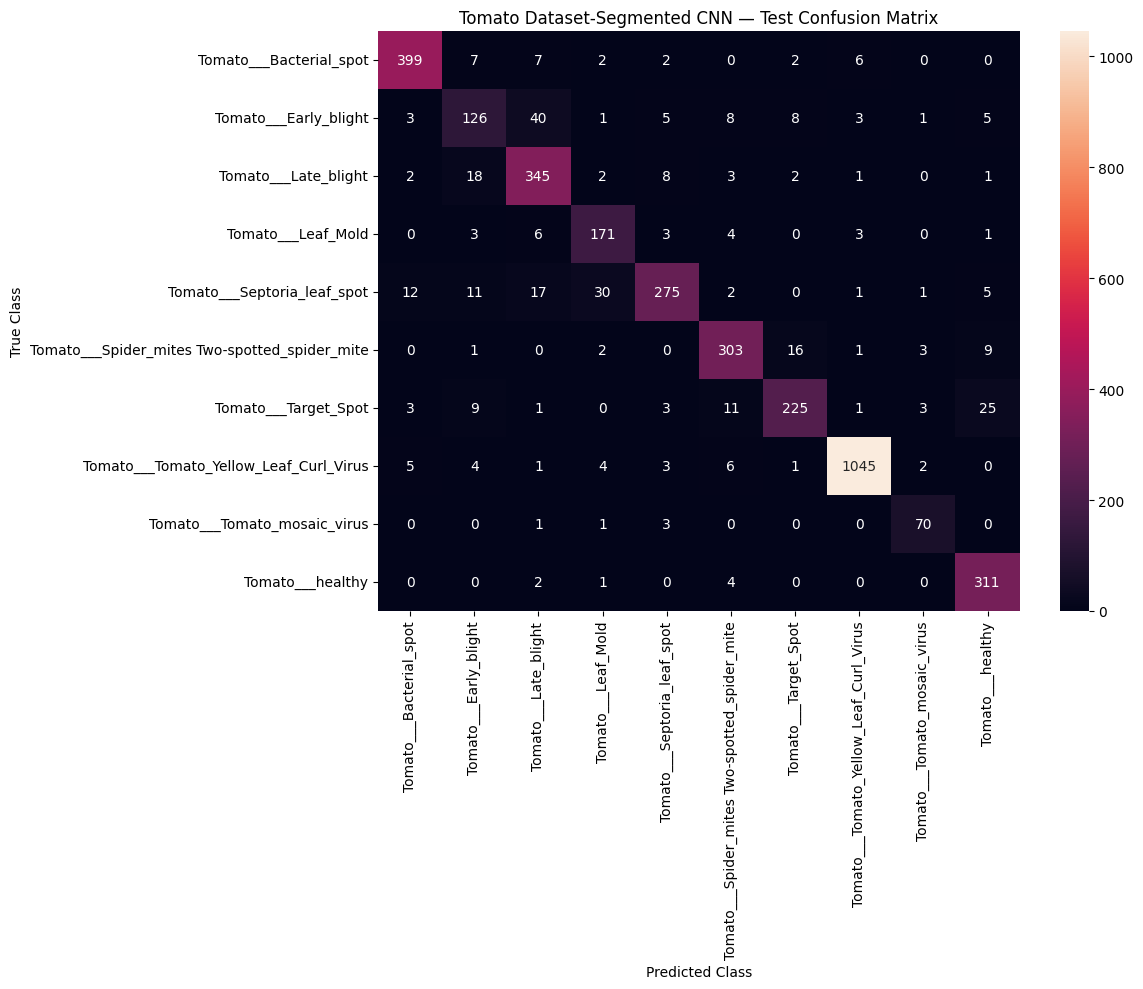


FINAL DATASET-SEGMENTED EXPERIMENT SUMMARY
Segmented dataset: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented
Classes: 10
Total images: 18160
Training images: 11622
Validation images: 2906
Testing images: 3632
Epochs completed: 12
Final test accuracy: 90.03%
Training time: 3.20 minutes
Test set used for training? NO
Results folder: /content/tomato_dataset_segmented_cnn_experiment

Saved files:
- tomato_dataset_segmented_accuracy.png
- tomato_dataset_segmented_classification_report.csv
- tomato_dataset_segmented_cnn_best.keras
- tomato_dataset_segmented_confusion_matrix.csv
- tomato_dataset_segmented_confusion_matrix.png
- tomato_dataset_segmented_loss.png
- tomato_dataset_segmented_overall_metrics.csv
- tomato_dataset_segmented_split.csv
- tomato_dataset_segmented_test_predictions.csv
- tomato_dataset_segmented_training_history.csv
- tomato_dataset_segmented_training_log.csv


In [ ]:

# ============================================================
# TOMATO DISEASE CLASSIFICATION — DATASET-PROVIDED SEGMENTED IMAGES
# FULL TRAINING + FINAL EVALUATION
#
# Same CNN architecture and hyperparameters as raw-image experiment
# 64% TRAIN | 16% VALIDATION | 20% TEST
# ============================================================

# ============================================================
# 1. IMPORTS
# ============================================================

import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

# ============================================================
# 2. CONFIGURATION
# ============================================================

IMAGE_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 50
RANDOM_STATE = 42

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

OUTPUT_DIR = Path("/content/tomato_dataset_segmented_cnn_experiment")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

# ============================================================
# 3. DOWNLOAD / LOCATE PLANTVILLAGE DATASET
# ============================================================

print("\nLocating PlantVillage dataset...")

download_path = Path(
    kagglehub.dataset_download(
        "abdallahalidev/plantvillage-dataset"
    )
)

print("Downloaded dataset location:", download_path)

# Search for likely segmented-folder names.
# The actual directory name must be verified before training.
candidate_names = {
    "segmented",
    "segmented images",
    "segmented_images",
    "segmented images dataset",
    "segmented_images_dataset"
}

candidate_dirs = []

for directory in download_path.rglob("*"):
    if not directory.is_dir():
        continue

    if directory.name.lower() in candidate_names:
        # A useful class-level folder should contain Tomato___ folders.
        tomato_dirs = [
            p for p in directory.iterdir()
            if p.is_dir() and p.name.startswith("Tomato___")
        ]

        if tomato_dirs:
            candidate_dirs.append(directory)

if not candidate_dirs:
    raise FileNotFoundError(
        "Could not automatically identify the dataset-provided "
        "segmented folder containing Tomato___ class directories.\n"
        f"Dataset root: {download_path}\n"
        "Inspect the dataset folder structure and set SEGMENTED_ROOT "
        "to the exact segmented directory before running the CNN."
    )

if len(candidate_dirs) > 1:
    print("\nMultiple possible segmented folders found:")
    for i, path in enumerate(candidate_dirs):
        print(f"{i}: {path}")

    # Prefer the folder with the most tomato images.
    def tomato_image_count(root):
        return sum(
            1 for class_dir in root.iterdir()
            if class_dir.is_dir() and class_dir.name.startswith("Tomato___")
            for image_path in class_dir.iterdir()
            if image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        )

    SEGMENTED_ROOT = max(candidate_dirs, key=tomato_image_count)
else:
    SEGMENTED_ROOT = candidate_dirs[0]

print("\nUsing segmented folder:", SEGMENTED_ROOT)

# ============================================================
# 4. COLLECT SEGMENTED TOMATO IMAGES
# ============================================================

class_folders = sorted([
    p for p in SEGMENTED_ROOT.iterdir()
    if p.is_dir()
    and p.name.startswith("Tomato___")
    and any(
        f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        for f in p.iterdir()
    )
])

if len(class_folders) < 2:
    raise ValueError(
        "The selected segmented folder does not contain at least "
        "two tomato classes."
    )

TOMATO_CLASSES = [folder.name for folder in class_folders]

class_to_index = {
    name: i for i, name in enumerate(TOMATO_CLASSES)
}

records = []

for folder in class_folders:
    images = sorted([
        p for p in folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    ])

    for image_path in images:
        records.append({
            "image_path": str(image_path),
            "image_id": image_path.stem,
            "class_name": folder.name,
            "label": class_to_index[folder.name]
        })

data_df = pd.DataFrame(records)

if data_df.empty:
    raise ValueError("No segmented tomato images found.")

print("\nNumber of tomato classes:", len(TOMATO_CLASSES))
print("Total segmented images:", len(data_df))
print("\nClass counts:")
print(data_df["class_name"].value_counts().sort_index())

# ============================================================
# 5. SPLIT DATA — 64% / 16% / 20%
# ============================================================

# This preserves the split procedure and random seed used previously.
# It does NOT guarantee the same exact images as the raw experiment
# unless that experiment's saved split is reused.

train_pool_df, test_df = train_test_split(
    data_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=data_df["label"]
)

train_df, val_df = train_test_split(
    train_pool_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=train_pool_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nDataset split:")
print(f"Training:   {len(train_df)} ({100*len(train_df)/len(data_df):.2f}%)")
print(f"Validation: {len(val_df)} ({100*len(val_df)/len(data_df):.2f}%)")
print(f"Testing:    {len(test_df)} ({100*len(test_df)/len(data_df):.2f}%)")

split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

split_df.to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_split.csv",
    index=False
)

print("\nClass-wise split counts:")
print(pd.crosstab(split_df["class_name"], split_df["split"]))

# ============================================================
# 6. IMAGE PREPROCESSING
# ============================================================

def load_and_preprocess_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, tf.cast(label, tf.int32)


def create_dataset(frame, shuffle=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(
        load_and_preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 5000),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


print("\nBuilding datasets...")
train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Test batches:", len(test_ds))

# ============================================================
# 7. CLASS WEIGHTS
# ============================================================

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(TOMATO_CLASSES)),
    y=train_df["label"].to_numpy()
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:")
for i, name in enumerate(TOMATO_CLASSES):
    print(f"{name}: {class_weights[i]:.4f}")

# ============================================================
# 8. BUILD CNN FROM SCRATCH — SAME ARCHITECTURE
# ============================================================

tf.keras.backend.clear_session()
tf.random.set_seed(RANDOM_STATE)

model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    ),

    tf.keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(
        len(TOMATO_CLASSES),
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nCNN architecture:")
model.summary()

# ============================================================
# 9. VERIFY FIRST BATCH
# ============================================================

print("\nTesting first training batch...", flush=True)
start = time.time()

for images, labels in train_ds.take(1):
    print("Batch loaded successfully.")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

print("First batch load time:", round(time.time() - start, 2), "seconds")

# ============================================================
# 10. TRAIN CNN
# ============================================================

BEST_MODEL_PATH = OUTPUT_DIR / "tomato_dataset_segmented_cnn_best.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(OUTPUT_DIR / "tomato_dataset_segmented_training_log.csv")
    ),

    tf.keras.callbacks.LambdaCallback(
        on_epoch_end=lambda epoch, logs: print(
            f"\nEpoch {epoch+1} finished | "
            f"loss={logs['loss']:.4f} | "
            f"accuracy={logs['accuracy']:.4f} | "
            f"val_loss={logs['val_loss']:.4f} | "
            f"val_accuracy={logs['val_accuracy']:.4f}",
            flush=True
        )
    )
]

print("\nStarting segmented-image CNN training...", flush=True)
training_start = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1
)

training_time = time.time() - training_start

print(f"\nTraining completed in {training_time/60:.2f} minutes.")

pd.DataFrame(history.history).to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_training_history.csv",
    index=False
)

# ============================================================
# 11. TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Tomato Dataset-Segmented CNN — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_dataset_segmented_accuracy.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Tomato Dataset-Segmented CNN — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tomato_dataset_segmented_loss.png", dpi=300)
plt.show()

# ============================================================
# 12. VALIDATION AND FINAL TEST EVALUATION
# ============================================================

best_model = tf.keras.models.load_model(str(BEST_MODEL_PATH))

val_loss, val_accuracy = best_model.evaluate(val_ds, verbose=1)

print("\nVALIDATION RESULTS")
print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print("\nFINAL TEST RESULTS")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

# ============================================================
# 13. CLASSIFICATION REPORT AND METRICS
# ============================================================

probabilities = best_model.predict(test_ds, verbose=1)

y_true = test_df["label"].to_numpy()
y_pred = np.argmax(probabilities, axis=1)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES))),
    target_names=TOMATO_CLASSES,
    digits=4,
    zero_division=0
))

report_df = pd.DataFrame(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(TOMATO_CLASSES))),
        target_names=TOMATO_CLASSES,
        output_dict=True,
        zero_division=0
    )
).transpose()

report_df.to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_classification_report.csv"
)

overall_metrics = {
    "test_loss": test_loss,
    "test_accuracy": accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "weighted_precision": precision_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_recall": recall_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "weighted_f1": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "test_image_count": len(y_true),
    "training_time_minutes": training_time / 60
}

print("\nOVERALL METRICS")
for name, value in overall_metrics.items():
    print(f"{name}: {value}")

pd.DataFrame([overall_metrics]).to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_overall_metrics.csv",
    index=False
)

# ============================================================
# 14. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(TOMATO_CLASSES)))
)

print("\nCONFUSION MATRIX")
print(cm)

pd.DataFrame(
    cm,
    index=TOMATO_CLASSES,
    columns=TOMATO_CLASSES
).to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_confusion_matrix.csv"
)

plt.figure(figsize=(
    max(12, len(TOMATO_CLASSES) * 0.8),
    max(10, len(TOMATO_CLASSES) * 0.7)
))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=TOMATO_CLASSES,
    yticklabels=TOMATO_CLASSES
)

plt.title("Tomato Dataset-Segmented CNN — Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "tomato_dataset_segmented_confusion_matrix.png",
    dpi=300
)
plt.show()

# ============================================================
# 15. SAVE TEST PREDICTIONS AND FINAL SUMMARY
# ============================================================

predictions_df = test_df.copy()
predictions_df["predicted_label"] = y_pred
predictions_df["predicted_class"] = [
    TOMATO_CLASSES[i] for i in y_pred
]
predictions_df["confidence"] = np.max(probabilities, axis=1)
predictions_df["correct"] = y_true == y_pred

predictions_df.to_csv(
    OUTPUT_DIR / "tomato_dataset_segmented_test_predictions.csv",
    index=False
)

print("\n" + "=" * 60)
print("FINAL DATASET-SEGMENTED EXPERIMENT SUMMARY")
print("=" * 60)

print("Segmented dataset:", SEGMENTED_ROOT)
print("Classes:", len(TOMATO_CLASSES))
print("Total images:", len(data_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Epochs completed:", len(history.history["loss"]))
print(f"Final test accuracy: {test_accuracy*100:.2f}%")
print(f"Training time: {training_time/60:.2f} minutes")
print("Test set used for training? NO")
print("Results folder:", OUTPUT_DIR)

print("\nSaved files:")
for file in sorted(OUTPUT_DIR.iterdir()):
    if file.is_file():
        print("-", file.name)
